In [1]:
# libraries import

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Customer Dataset

data = {
    "Customer_ID": [101, 102, 103, 104, 105, 106, 107, 108, 109, 110],
    "Age": [22, 35, 45, 28, 52, 31, 40, 24, 48, 36],
    "Gender": [
        "Female", "Male", "Female", "Male", "Female",
        "Male", "Female", "Female", "Male", "Male"
    ],
    "Location": [
        "Pune", "Mumbai", "Pune", "Nashik", "Mumbai",
        "Pune", "Nashik", "Mumbai", "Pune", "Nashik"
    ],
    "Purchase_Amount": [
        1500, 3000, 4500, 2000, 6000,
        2500, 5000, 1800, 4000, 3500
    ],
    "Previous_Purchases": [2, 5, 8, 3, 10, 4, 7, 2, 6, 5]
}

df = pd.DataFrame(data)

df.head(10)

,Customer_ID,Age,Gender,Location,Purchase_Amount,Previous_Purchases
0,101,22,Female,Pune,1500,2
1,102,35,Male,Mumbai,3000,5
2,103,45,Female,Pune,4500,8
3,104,28,Male,Nashik,2000,3
4,105,52,Female,Mumbai,6000,10
5,106,31,Male,Pune,2500,4
6,107,40,Female,Nashik,5000,7
7,108,24,Female,Mumbai,1800,2
8,109,48,Male,Pune,4000,6
9,110,36,Male,Nashik,3500,5


In [3]:
# dataset information

print("Dataset Shape:", df.shape)
df.info()

Dataset Shape: (10, 6)
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Customer_ID         10 non-null     int64
 1   Age                 10 non-null     int64
 2   Gender              10 non-null     str  
 3   Location            10 non-null     str  
 4   Purchase_Amount     10 non-null     int64
 5   Previous_Purchases  10 non-null     int64
dtypes: int64(4), str(2)
memory usage: 612.0 bytes


In [4]:
# Missing values

print(df.isnull().sum())

Customer_ID           0
Age                   0
Gender                0
Location              0
Purchase_Amount       0
Previous_Purchases    0
dtype: int64


In [5]:
# Duplicate records

print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [6]:
# customer Segmentation based on age 

df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 25, 35, 45, 100],
    labels=["18-25", "26-35", "36-45", "46+"]
)

df[["Customer_ID", "Age", "Age_Group", "Purchase_Amount"]]

,Customer_ID,Age,Age_Group,Purchase_Amount
0,101,22,18-25,1500
1,102,35,26-35,3000
2,103,45,36-45,4500
3,104,28,26-35,2000
4,105,52,46+,6000
5,106,31,26-35,2500
6,107,40,36-45,5000
7,108,24,18-25,1800
8,109,48,46+,4000
9,110,36,36-45,3500


In [7]:
# Analysis based on location

location_analysis = df.groupby("Location").agg(
    Total_Customers=("Customer_ID", "count"),
    Total_Purchases=("Purchase_Amount", "sum"),
    Average_Purchase=("Purchase_Amount", "mean")
)

location_analysis

,Total_Customers,Total_Purchases,Average_Purchase
Location,,,
Mumbai,3,10800,3600.0
Nashik,3,10500,3500.0
Pune,4,12500,3125.0


In [8]:
# Age group-wise Purchase Analysis

age_analysis = df.groupby("Age_Group", observed=False).agg(
    Total_Customers=("Customer_ID", "count"),
    Total_Purchases=("Purchase_Amount", "sum"),
    Average_Purchase=("Purchase_Amount", "mean")
)

age_analysis

,Total_Customers,Total_Purchases,Average_Purchase
Age_Group,,,
18-25,2,3300,1650.000000
26-35,3,7500,2500.000000
36-45,3,13000,4333.333333
46+,2,10000,5000.000000


In [9]:
# Identifying the Customer with the Highest Purchase

top_customers = df.sort_values(
    by="Purchase_Amount",
    ascending=False
)

top_customers[
    ["Customer_ID", "Age", "Location", "Purchase_Amount"]
]

,Customer_ID,Age,Location,Purchase_Amount
4,105,52,Mumbai,6000
6,107,40,Nashik,5000
2,103,45,Pune,4500
8,109,48,Pune,4000
9,110,36,Nashik,3500
1,102,35,Mumbai,3000
5,106,31,Pune,2500
3,104,28,Nashik,2000
7,108,24,Mumbai,1800
0,101,22,Pune,1500


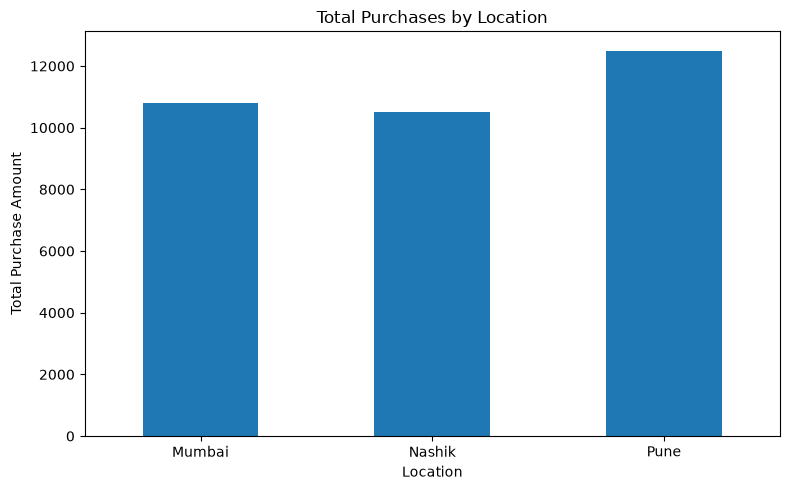

In [10]:
# Bar Chart of Total Purchaese by Location

location_analysis["Total_Purchases"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Total Purchases by Location")
plt.xlabel("Location")
plt.ylabel("Total Purchase Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

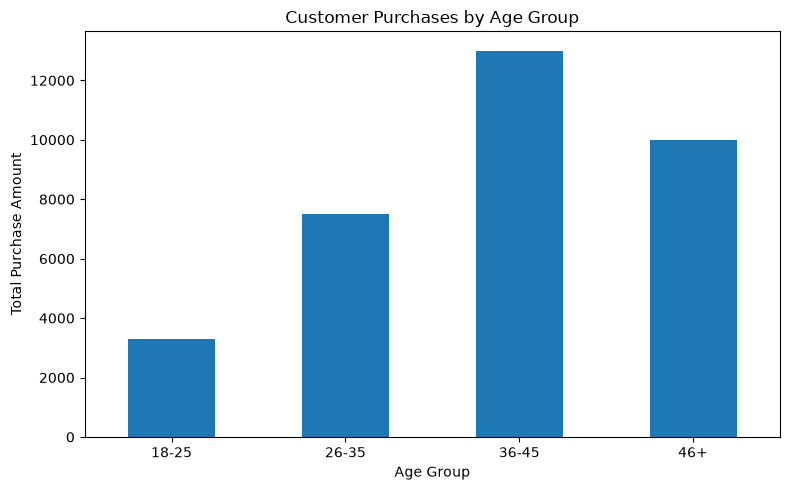

In [11]:
#  Chart pf total Purchases by Age Group

age_analysis["Total_Purchases"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Customer Purchases by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Purchase Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# Bonus - marketing strategies

### Marketing Strategies

1. Targeted Discounts: Offer discounts based on customers' purchase history.

2. Loyalty Programs: Reward frequent customers with loyalty points.

3. Location-Based Marketing: Create offers based on purchasing patterns in different cities.

4. Age-Based Campaigns: Select suitable products and promotions for different age groups.

5. Customer Retention: Provide special offers to customers who have not made a purchase for a long time.